# Expert-choice M-MoE on MNIST: a hands-on tutorial

This notebook trains the **multi-head mixture-of-experts MLP encoder with expert-choice routing** (M-MoE, EC)
from this repo on MNIST, and changes **one hyperparameter at a time** to show what each one controls and
what it affects.

**Why MNIST.** The model learns *which input features each expert reads*. On MNIST the features are the 784
pixels, so every expert's input set can be drawn as a 28×28 image (its *receptive field*). You can see the
grouping, the null (ignored pixels) and the input budget directly.

**The task.** As in the original lab-data work, the model is an **autoencoder**: encoder → z (64-d) →
decoder → reconstruct all pixels. Labels are never used for training. They are only used for a **linear
probe** (logistic regression on z), which measures how much digit information the embedding holds.

**What to look at for every run**

| metric | meaning |
|---|---|
| `val_recon` / `test_recon` | reconstruction loss (Huber, δ = 1: ≈ ½·MSE on [0, 1] pixels). Lower is better. |
| `probe_acc` | linear-probe digit accuracy on z (test set) |
| `kept_h*` | pixels the head keeps (not in its null) |
| `orphan_h*` | kept pixels that **no** expert picked (in, but unused) |
| `mem_h*` | mean number of experts reading a kept pixel (overlap) |
| `changed_h*` | share of **all** (pixel, expert) pairs whose membership differs from the initial assignment (gained or lost). Not the share of memberships that moved: each expert holds only k of 784 pixels, so for that multiply by ≈ 784 / (2k), i.e. ×1 (head 0), ×4 (head 1), ×15.7 (head 2) |
| `eff_params` | encoder weights actually used after hardening (masked weights excluded) |

Each run trains for 20 epochs (≈ 30 s on a GPU): dense warm-up for epochs 0–2, gate learning for 3–13,
hard gates from epoch 14 on. Only hardened epochs can be selected as the checkpoint.

**Contents**
0. Setup
1. Baseline run: training phases, receptive fields, null, reconstructions
2. Architecture: `experts_per_head`, `expert_hidden` / `expert_out`
3. Routing capacity: `r` (and `capacity`)
4. The null: `lambda_null`, `null_type` / `null_q`, `null_mode`, `keep_init`
5. Initialisation: `gate_init`, `train_gates`, `init_scale`, seed stability
6. The gate schedule: `phases.*` (warm-up, gate LR, temperature)
7. Expert-choice gradient and exploration: `ec_surrogate`, `ec_noise`, `lambda_mem`
8. Global input budget: `input_budget`, `budget_type`
9. Missing data: `use_obs_flags`, `column_units`, `split_value_flag` (occluded MNIST)
10. Summary table and cheat sheet

## 0. Setup

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as Fn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import yaml

from mmoe import fit, model_config, train_config, encode, evaluate_recon, head_diagnostics, abs_corr_prior
from mmoe.config import merge
from mmoe.data import load_mnist, occlude

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, "| torch", torch.__version__)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

d = load_mnist(ROOT / "data")
(Xtr, ytr), (Xva, yva), (Xte, yte) = d["train"], d["val"], d["test"]
print("train", Xtr.shape, "val", Xva.shape, "test", Xte.shape)

BASE = yaml.safe_load((ROOT / "configs" / "mnist.yaml").read_text())
print(yaml.safe_dump(BASE))
PRIOR = abs_corr_prior(Xtr, None, min_coobs=50)        # |corr| between pixels, train split only

device: cuda | torch 2.8.0+cu129


train (50000, 784) val (10000, 784) test (10000, 784)
model:
  phases:
    harden_start: 14
    lambda_ramp_end: 8
    warmup_end: 3
  use_obs_flags: false
train:
  epochs: 20
  warmup_epochs: 1



In [2]:
RESULTS = {}          # name -> dict(res=FitResult, metrics=dict)

def probe(Ztr, ytr, Zte, yte):
    # Linear probe: multinomial logistic regression on standardised z (L-BFGS on the GPU).
    Ztr, Zte = (torch.tensor(a, device=DEV, dtype=torch.float32) for a in (Ztr, Zte))
    ytr_t, yte_t = (torch.tensor(a, device=DEV) for a in (ytr, yte))
    mu, sd = Ztr.mean(0), Ztr.std(0) + 1e-6
    lin = nn.Linear(Ztr.shape[1], 10).to(DEV)
    opt = torch.optim.LBFGS(lin.parameters(), max_iter=300, line_search_fn="strong_wolfe")
    def closure():
        opt.zero_grad()
        loss = Fn.cross_entropy(lin((Ztr - mu) / sd), ytr_t) + 1e-4 * lin.weight.pow(2).sum()
        loss.backward(); return loss
    opt.step(closure)
    with torch.no_grad():
        return float((lin((Zte - mu) / sd).argmax(1) == yte_t).float().mean())

def run(name, model=None, train=None, data=None, quiet=True):
    # Train BASE + overrides (cached by name) and compute the metrics listed at the top.
    if name in RESULTS:
        return RESULTS[name]
    mc = model_config(merge(BASE.get("model", {}), model or {}))
    tc = train_config(merge(BASE.get("train", {}), train or {}))
    data = data or {"train": (Xtr, None), "val": (Xva, None), "test": (Xte, None)}
    prior = PRIOR if data["train"][1] is None else abs_corr_prior(*data["train"], min_coobs=50)
    t0 = time.time()
    res = fit(mc, tc, {"train": data["train"], "val": data["val"]}, abs_corr=prior, verbose=not quiet)
    obs = (lambda o: o if mc.use_obs_flags else None)
    Ztr, Htr = encode(res.model, data["train"][0], obs(data["train"][1]), heads=True)
    Zte, Hte = encode(res.model, data["test"][0], obs(data["test"][1]), heads=True)
    xt = torch.tensor(data["test"][0], device=DEV)
    ot = torch.tensor(data["test"][1], device=DEV) if (mc.use_obs_flags and data["test"][1] is not None) else None
    m = {"val_recon": res.best_val, "test_recon": evaluate_recon(res.model, xt, ot, tc)["recon"],
         "probe_acc": probe(Ztr, ytr, Zte, yte), "best_epoch": res.best_epoch,
         "eff_params": res.params["encoder_effective_params_final"], "dense_params": res.params["encoder_params"]}
    for dg, (hz_tr, hz_te) in zip(head_diagnostics(res.model.encoder), zip(Htr, Hte)):
        h = dg["head"]
        m.update({f"kept_h{h}": dg["n_kept"], f"orphan_h{h}": dg["n_orphan"],
                  f"mem_h{h}": round(dg["mean_memberships"], 2), f"changed_h{h}": round(dg["changed_vs_init"], 3),
                  f"k_h{h}": dg["k"], f"probe_h{h}": probe(hz_tr, ytr, hz_te, yte)})
    if res.model.encoder.input_gate is not None:
        m.update(res.model.encoder.input_gate.summary())
    m["seconds"] = round(time.time() - t0, 1)
    RESULTS[name] = {"res": res, "metrics": m, "mcfg": mc}
    print(f"{name:28s} val {m['val_recon']:.5f}  test {m['test_recon']:.5f}  probe {m['probe_acc']:.4f}  "
          f"({m['seconds']} s)")
    return RESULTS[name]

def table(names, cols=None):
    df = pd.DataFrame({n: RESULTS[n]["metrics"] for n in names}).T
    cols = cols or ["val_recon", "test_recon", "probe_acc", "eff_params"]
    return df[[c for c in cols if c in df.columns]]

In [3]:
# ---- plotting helpers ----
def hard(name):
    # Per head: (G [U, m], keep [U]) as numpy.
    return [(G.cpu().numpy(), k.cpu().numpy()) for G, k in RESULTS[name]["res"].model.encoder.hard_assignments()]

def assignment_map(G, keep, logits):
    # Pixel -> primary expert (highest logit among the experts that picked it); -1 null, -2 orphan.
    U = G.shape[0]
    a = np.where(G > 0, logits, -np.inf).argmax(1).astype(float)
    a[(keep > 0) & (G.sum(1) == 0)] = -2
    a[keep == 0] = -1
    return a[:784].reshape(28, 28)

def show_maps(name, title=None, heads=None):
    # One image per head: colour = primary expert, white = null, black = orphan.
    enc = RESULTS[name]["res"].model.encoder
    hs = hard(name)
    heads = range(len(hs)) if heads is None else heads
    fig, axes = plt.subplots(1, len(heads), figsize=(3.1 * len(heads), 3.2), squeeze=False)
    for ax, h in zip(axes[0], heads):
        G, keep = hs[h]
        a = assignment_map(G, keep, enc.heads[h].gate.logits.detach().cpu().numpy())
        m = G.shape[1]
        cmap = ListedColormap(["black", "white"] + list(plt.cm.tab20(np.linspace(0, 1, 20))) * (m // 20 + 1))
        ax.imshow(a + 2, cmap=cmap, vmin=0, vmax=len(cmap.colors) - 1, interpolation="nearest")
        ax.set_title(f"head {h}: m={m}, k={enc.heads[h].gate.k}\nkept {int(keep[:784].sum())}, "
                     f"orphan {int(((keep > 0) & (G.sum(1) == 0))[:784].sum())}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title or name, fontsize=11); plt.tight_layout(); plt.show()

def show_experts(name, h, n=16, cols=8):
    # Receptive field of each expert (pixels it reads), first n experts of head h.
    G, keep = hard(name)[h]
    n = min(n, G.shape[1]); rows = int(np.ceil(n / cols)); cols = min(cols, n)
    fig, axes = plt.subplots(rows, cols, figsize=(1.6 * cols, 1.7 * rows), squeeze=False)
    for j, ax in enumerate(axes.flat):
        ax.axis("off")
        if j < n:
            ax.imshow(G[:784, j].reshape(28, 28), cmap="Greys", vmin=0, vmax=1)
            ax.set_title(f"e{j} ({int(G[:, j].sum())})", fontsize=8)
    fig.suptitle(f"{name}: head {h} receptive fields", fontsize=10); plt.tight_layout(); plt.show()

def show_keep(names, h=0, title="keep map (white = kept)"):
    fig, axes = plt.subplots(1, len(names), figsize=(2.6 * len(names), 2.9), squeeze=False)
    for ax, n in zip(axes[0], names):
        keep = hard(n)[h][1][:784]
        ax.imshow(keep.reshape(28, 28), cmap="gray", vmin=0, vmax=1); ax.axis("off")
        ax.set_title(f"{n}\nkept {int(keep.sum())}", fontsize=8)
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

def plot_history(name, cols=("train_recon", "val_recon")):
    hst = RESULTS[name]["res"].history
    mc = RESULTS[name]["mcfg"]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
    for c in cols: axes[0].plot(hst.epoch, hst[c], label=c)
    axes[0].set_yscale("log"); axes[0].set_title("loss"); axes[0].legend()
    for c in [c for c in hst.columns if c.endswith("_n_kept")]: axes[1].plot(hst.epoch, hst[c], label=c[:2])
    axes[1].set_title("kept units per head"); axes[1].legend()
    for c in [c for c in hst.columns if c.endswith("_changed_vs_init")]: axes[2].plot(hst.epoch, hst[c], label=c[:2])
    ax2 = axes[2].twinx(); ax2.plot(hst.epoch, hst.temperature, "k--", lw=1); ax2.set_ylabel("temperature (dashed)")
    axes[2].set_title("routing changed vs init"); axes[2].legend(loc="upper left")
    for ax in axes:
        ax.axvspan(0, mc.phases.warmup_end, color="tab:orange", alpha=0.08)
        ax.axvspan(mc.phases.harden_start, hst.epoch.max() + 0.5, color="tab:green", alpha=0.08)
        ax.set_xlabel("epoch")
    fig.suptitle(f"{name}  (orange = dense warm-up, white = gate learning, green = hardened)", fontsize=10)
    plt.tight_layout(); plt.show()

def bars(names, metric, ax=None, title=None):
    v = [RESULTS[n]["metrics"][metric] for n in names]
    ax = ax or plt.gca()
    ax.bar(range(len(v)), v, color="tab:blue"); ax.set_xticks(range(len(v)), names, rotation=30, ha="right", fontsize=8)
    lo, hi = min(v), max(v); pad = (hi - lo) * 0.3 + 1e-9
    ax.set_ylim(max(0, lo - pad), hi + pad); ax.set_title(title or metric, fontsize=9)

def compare(names, metrics=("test_recon", "probe_acc", "eff_params")):
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.2 * len(metrics), 3.2))
    for ax, m in zip(np.atleast_1d(axes), metrics): bars(names, m, ax)
    plt.tight_layout(); plt.show()

## 1. Baseline run

Defaults from `configs/default.yaml`, with the MNIST overrides in `configs/mnist.yaml`:

* 3 heads with **4, 16 and 64 experts**; each expert is a tiny MLP (784 → u = 16 → d_e = 2)
* **expert choice, r = 2**: expert j of head h reads its top-k pixels, k = ⌈r·784/m⌉ (392, 98 and 25)
* **learned per-head null**: a hard-concrete keep gate per pixel and head, with an L0 price λ_null = 1e-3
* **`prior_corr` init**: routing logits start from spectral clustering of the pixel |correlation|
* `use_obs_flags: false`: MNIST has no missing values, so the input is the 784 pixel values only

In [4]:
r = run("baseline", quiet=False)
pd.Series(r["metrics"])

ep   0 ph 0 train 0.0441 val 0.0168 best inf@-1 (1.0s)


ep   1 ph 0 train 0.0154 val 0.0100 best inf@-1 (0.8s)


ep   2 ph 0 train 0.0111 val 0.0081 best inf@-1 (0.8s)


ep   3 ph 1 train 0.0152 val 0.0089 best inf@-1 (1.4s)


ep   4 ph 1 train 0.0102 val 0.0080 best inf@-1 (1.4s)


...

ep  17 ph 2 train 0.0071 val 0.0056 best 0.0056@17 (0.7s)


ep  18 ph 2 train 0.0071 val 0.0056 best 0.0056@18 (0.7s)


ep  19 ph 2 train 0.0071 val 0.0056 best 0.0056@19 (0.7s)


baseline                     val 0.00562  test 0.00547  probe 0.9120  (38.1 s)


val_recon       5.624039e-03
test_recon      5.468058e-03
probe_acc       9.120000e-01
best_epoch      1.900000e+01
eff_params      9.079200e+04
dense_params    1.136920e+06
kept_h0         4.890000e+02
orphan_h0       0.000000e+00
mem_h0          3.210000e+00
changed_h0      2.500000e-01
k_h0            3.920000e+02
probe_h0        5.043000e-01
kept_h1         4.910000e+02
orphan_h1       3.000000e+00
mem_h1          3.190000e+00
changed_h1      1.230000e-01
k_h1            9.800000e+01
probe_h1        8.235000e-01
kept_h2         4.460000e+02
orphan_h2       2.100000e+01
mem_h2          3.590000e+00
changed_h2      3.600000e-02
k_h2            2.500000e+01
probe_h2        9.114000e-01
seconds         3.810000e+01
dtype: float64

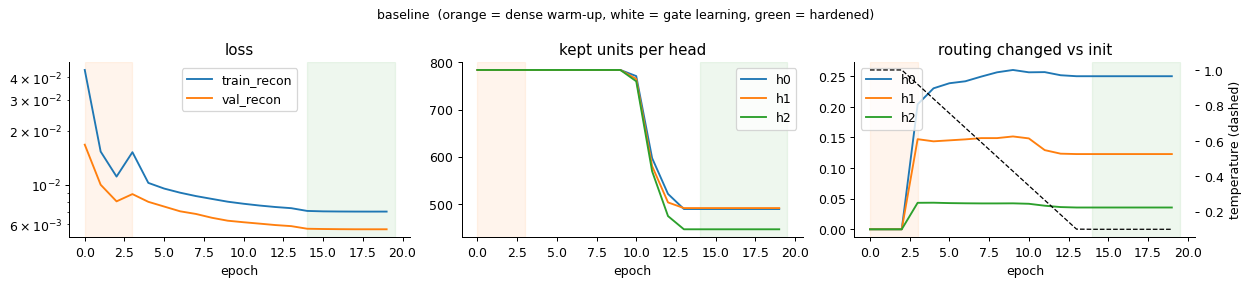

In [5]:
plot_history("baseline")

**Reading the curves.** Phase 0 (orange) is a plain dense MLP, so the loss drops quickly. When gate
learning starts (epoch 3), the loss jumps briefly: the experts suddenly lose most of their inputs. Most
routing change (`changed vs init`) happens in that first gate-learning epoch and then plateaus. The
fine heads move most: about 25% of head 0's memberships, ≈ 50% of head 1's and ≈ 55% of head 2's change.
(The plotted values, 0.25 / 0.12 / 0.036, are rates over all pixel–expert pairs; see the metric table at the
top for the conversion.) The null acts later: P(keep) only crosses
0.5 once the temperature has fallen (≈ epochs 10–13), and then ~300 pixels, mostly the always-black
border, are dropped. At epoch 14 everything is hardened: from then on the model is a fixed sparse network
and only the weights are fine-tuned.

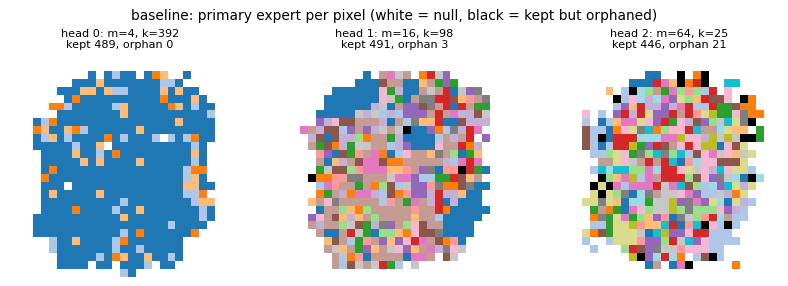

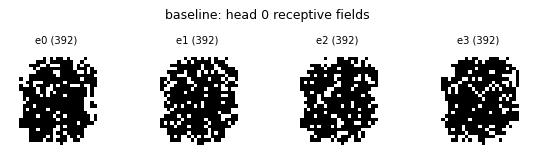

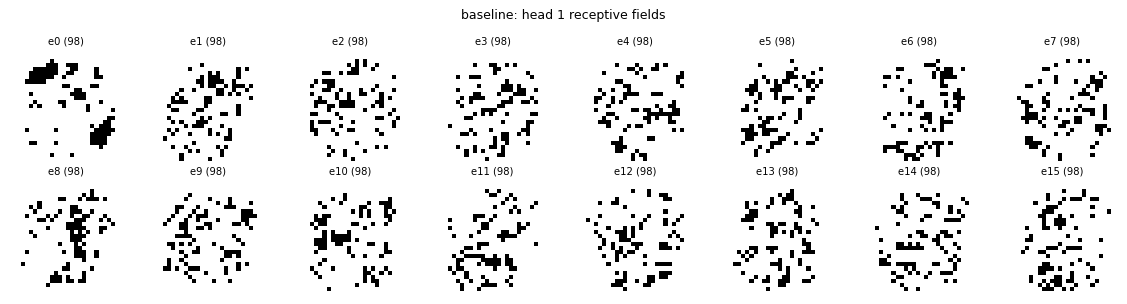

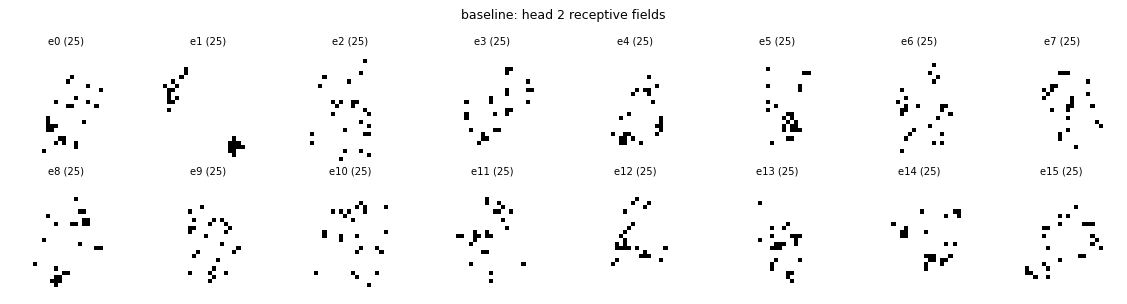

In [6]:
show_maps("baseline", "baseline: primary expert per pixel (white = null, black = kept but orphaned)")
show_experts("baseline", 0, n=4, cols=4)
show_experts("baseline", 1, n=16, cols=8)
show_experts("baseline", 2, n=16, cols=8)

**Receptive fields.** Head 0 (4 experts, k = 392) has each expert covering about half of the digit area,
with heavy overlap. In heads 1 and 2 (k = 98 and 25), each expert reads a **scattered** set of pixels, not
a compact spatial patch. Grouping follows the |correlation| prior, and on MNIST pixel correlation comes
from digit strokes, not adjacency. The initial clustering below is already scattered, and its one big
cluster is the constant border pixels, which correlate with nothing. Black pixels in the maps are
*orphans*: kept, but in no expert's top k. Under expert choice these appear in fine heads, where seats
are scarce. Each pixel has r = 2 seats per head on average, but some get more and some get none.

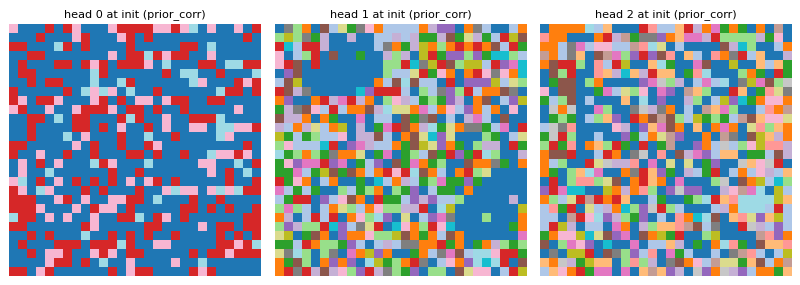

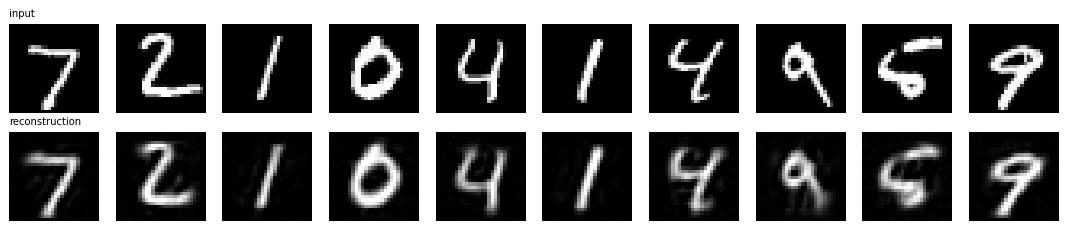

In [7]:
# Where did routing start? (prior_corr: spectral clusters of |corr|) vs where it ended.
enc = RESULTS["baseline"]["res"].model.encoder
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for h, ax in enumerate(axes):
    init = getattr(enc, f"init_mask{h}").cpu().numpy()
    ax.imshow(init.argmax(1)[:784].reshape(28, 28), cmap="tab20", interpolation="nearest"); ax.axis("off")
    ax.set_title(f"head {h} at init (prior_corr)", fontsize=9)
plt.tight_layout(); plt.show()

# Reconstructions
model = RESULTS["baseline"]["res"].model.eval()
with torch.no_grad():
    xb = torch.tensor(Xte[:10], device=DEV); rec = model(xb)[0].clamp(0, 1).cpu().numpy()
fig, axes = plt.subplots(2, 10, figsize=(12, 2.6))
for i in range(10):
    axes[0, i].imshow(Xte[i].reshape(28, 28), cmap="gray"); axes[1, i].imshow(rec[i].reshape(28, 28), cmap="gray")
    axes[0, i].axis("off"); axes[1, i].axis("off")
axes[0, 0].set_title("input", fontsize=8, loc="left"); axes[1, 0].set_title("reconstruction", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

## 2. Architecture

### 2a. `experts_per_head`: number of heads and the granularity of each

* **Controls:** how many heads there are and how many experts each head has. More experts per head means
  smaller groups (k = ⌈r·U/m⌉) and more, smaller output blocks (m·d_e numbers per head go to the readout).
* **Affects:** granularity of the learned groups, embedding quality, parameter count (W1 is stored densely,
  but only k·u weights per expert are used).
* **Research question:** does mixing coarse and fine heads beat any single granularity? (On MIMIC labs, yes:
  `[4]` alone was much worse, `[64]` alone close but slightly worse than `[4, 16, 64]`.)

heads=[4]                    val 0.01184  test 0.01165  probe 0.8285  (16.2 s)


heads=[16]                   val 0.00717  test 0.00700  probe 0.8933  (16.7 s)


heads=[64]                   val 0.00591  test 0.00575  probe 0.9077  (18.5 s)


,val_recon,test_recon,probe_acc,eff_params,probe_h0,probe_h1,probe_h2
heads=[4],0.011838,0.011652,0.8285,25864.0,0.8280,NaN,NaN
heads=[16],0.007171,0.007005,0.8933,28000.0,0.8936,NaN,NaN
heads=[64],0.005913,0.005747,0.9077,37056.0,0.9141,NaN,NaN
baseline,0.005624,0.005468,0.9120,90792.0,0.5043,0.8235,0.9114


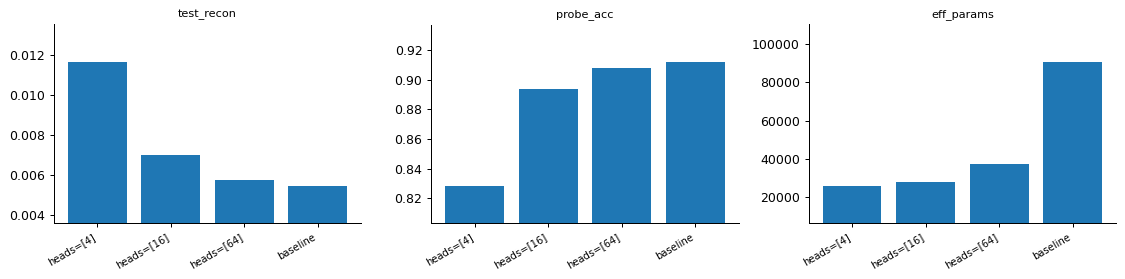

In [8]:
for eph in ([4], [16], [64]):
    run(f"heads={eph}", model={"experts_per_head": eph})
names = ["heads=[4]", "heads=[16]", "heads=[64]", "baseline"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "eff_params", "probe_h0", "probe_h1", "probe_h2"]))
compare(names)

`probe_h*` is a probe on each head's own output (m·d_e numbers) in the multi-head baseline. It shows what
each granularity contributes on its own.

**What we see.** Finer is better for a single head (`[4]` ≫ `[16]` > `[64]` in recon error and probe).
The multi-head model beats every single head on both. Inside the baseline, almost all digit information
sits in the fine head (`probe_h2` ≈ 0.91 vs `probe_h0` ≈ 0.50): the coarse head's 8 output numbers say
little about the digit on their own. Multi-head costs effective parameters (≈ 91k vs 37k for `[64]`).

### 2b. `expert_hidden` (u) and `expert_out` (d_e): size of each expert

* **Controls:** the width of each expert's hidden layer (u) and how many numbers each expert passes on
  (d_e). The readout input is Σ_h m_h·d_e.
* **Affects:** capacity per group. With d_e = 1 every group is squeezed into a single number, which makes
  experts easier to interpret but limits the information that gets through.

u8_de1                       val 0.00607  test 0.00592  probe 0.9115  (26.5 s)


u32_de4                      val 0.00521  test 0.00507  probe 0.9141  (31.0 s)


,val_recon,test_recon,probe_acc,eff_params,dense_params
u8_de1,0.006073,0.005918,0.9115,44756.0,601924.0
baseline,0.005624,0.005468,0.9120,90792.0,1136920.0
u32_de4,0.005212,0.005066,0.9141,186896.0,2210944.0


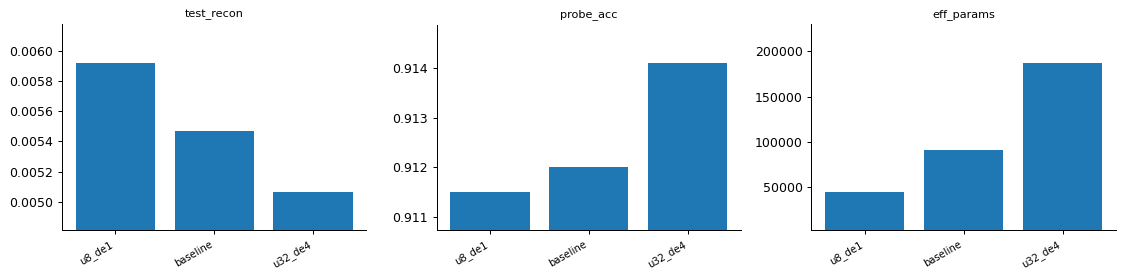

In [9]:
run("u8_de1", model={"expert_hidden": 8, "expert_out": 1})
run("u32_de4", model={"expert_hidden": 32, "expert_out": 4})
names = ["u8_de1", "baseline", "u32_de4"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "eff_params", "dense_params"]))
compare(names)

**What we see.** A plain capacity knob: recon improves steadily with expert size (parameters roughly
double at each step), and the probe barely moves (≈ 0.911–0.914). Even d_e = 1 (one number per group)
keeps the probe almost intact.

## 3. Routing capacity: `r` (and `capacity`)

* **Controls:** how many units each expert reads: k = ⌈r·U/m⌉ (U = 784 here; with a budget, U = K). r is
  the *average* number of experts per kept unit. Under expert choice, some units get more seats and some
  get none (orphans). `capacity: <int>` fixes k directly and ignores r.
* **Affects:** overlap between groups, how many pixels are orphaned, effective parameters (∝ r), and
  how close the model is to a dense MLP (large r ≈ dense).
* **Expect:** r = 1 gives near-partitions with more orphans and worse reconstruction. Larger r gives more
  overlap and better reconstruction, but the groups are less distinct.

r=1                          val 0.00587  test 0.00570  probe 0.9102  (33.0 s)


r=4                          val 0.00546  test 0.00531  probe 0.9135  (32.6 s)


,val_recon,test_recon,probe_acc,eff_params,k_h2,mem_h2,orphan_h0,orphan_h1,orphan_h2
r=1,0.005865,0.005703,0.9102,53416.0,13.0,2.01,6.0,19.0,51.0
baseline,0.005624,0.005468,0.9120,90792.0,25.0,3.59,0.0,3.0,21.0
r=4,0.005460,0.005311,0.9135,146856.0,49.0,6.53,0.0,2.0,5.0


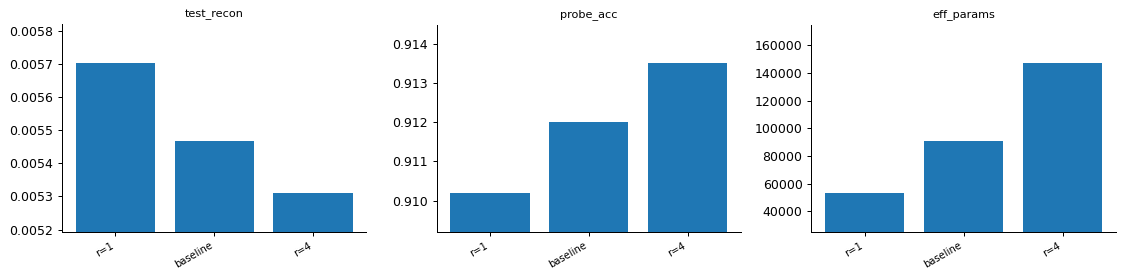

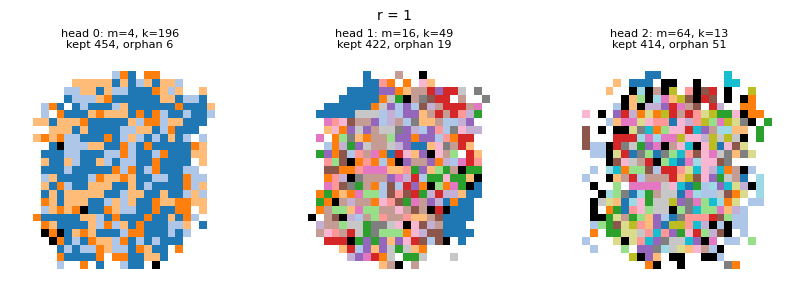

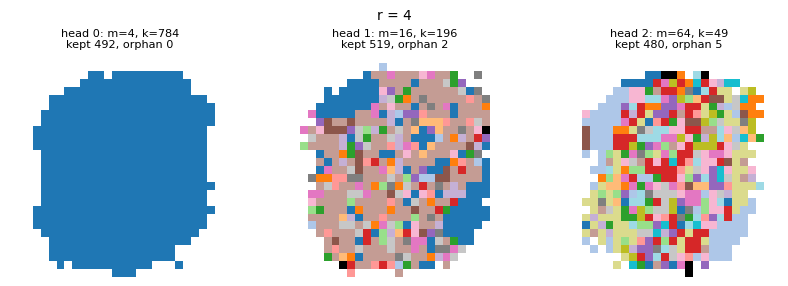

In [10]:
for rr in (1, 4):
    run(f"r={rr}", model={"r": rr})
names = ["r=1", "baseline", "r=4"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "eff_params", "k_h2", "mem_h2", "orphan_h0", "orphan_h1", "orphan_h2"]))
compare(names)
show_maps("r=1", "r = 1"); show_maps("r=4", "r = 4")

**What we see.** A monotone trade-off. Larger r gives lower recon error, slightly better probes, more
overlap (`mem_h2` ≈ 2 → 3.6 → 6.5) and far fewer orphans (head 2: ≈ 51 → 21 → 5). Effective parameters
grow roughly in proportion to r. `mem_h*` exceeds r because the null shrinks the kept set: k is computed
from all U units, but the seats are shared among fewer kept units. A fixed `capacity` avoids this
coupling.

## 4. The null (keep gates)

The null decides which units a head ignores entirely. Under expert choice, null units are **ineligible**,
so the experts' k seats go to the kept units.

### 4a. `lambda_null`: the price of keeping a unit (learned null)

* **Controls:** the L0 penalty λ·mean P(keep). Higher means more units are dropped.
* **Affects:** number of kept units, robustness (drops noisy or redundant features) and reconstruction
  of dropped features (they must be predicted from the others).
* **Note:** with a learned null the *data* decide how many units to drop. λ = 0 still drops units that
  actively hurt (rare), but mostly keeps everything.

lambda_null=0                val 0.00564  test 0.00548  probe 0.9124  (33.2 s)


lambda_null=0.01             val 0.00563  test 0.00548  probe 0.9120  (32.9 s)


,val_recon,test_recon,probe_acc,kept_h0,kept_h1,kept_h2
lambda_null=0,0.005638,0.005481,0.9124,784.0,784.0,784.0
baseline,0.005624,0.005468,0.9120,489.0,491.0,446.0
lambda_null=0.01,0.005633,0.005475,0.9120,307.0,383.0,337.0


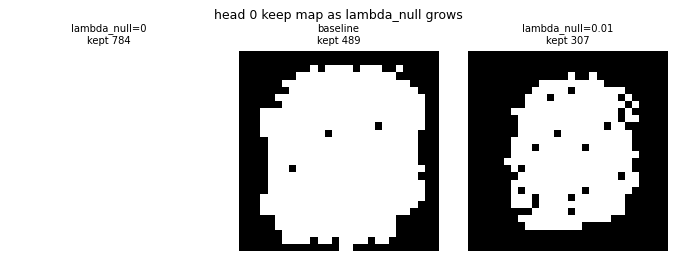

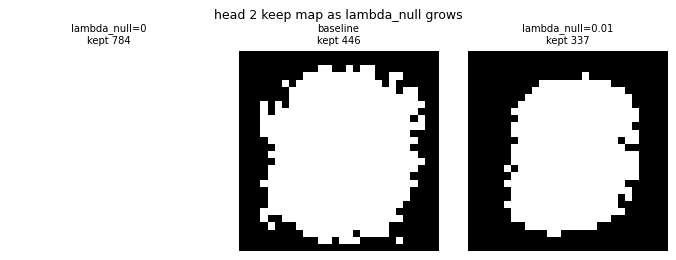

In [11]:
for lam in (0.0, 1e-2):
    run(f"lambda_null={lam:g}", model={"lambda_null": lam})
names = ["lambda_null=0", "baseline", "lambda_null=0.01"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "kept_h0", "kept_h1", "kept_h2"]))
show_keep(names, h=0, title="head 0 keep map as lambda_null grows")
show_keep(names, h=2, title="head 2 keep map as lambda_null grows")

**What we see.** λ_null sets the null size: λ = 0 keeps all 784 pixels, 1e-3 keeps ~490 (border dropped),
and 1e-2 keeps ~300–380 (it also eats into the digit's rim). Recon and probe are essentially unchanged.
The dropped pixels are predictable from the rest, which is exactly what an L0 price should find.

### 4b. `null_type` / `null_q`: learned vs fixed-size null

* `null_type: fixed` drops **exactly** a fraction `null_q` of units (those with the lowest keep logits,
  straight-through) and has no L0 price.
* **Research use:** a control for null *size*. If `learned` beats `fixed` at a similar size, the benefit
  comes from choosing *how many* to drop, not only *which*.

### 4c. `null_mode`: per head, shared, or off

* `per_head`: each head has its own keep gate, so a fine head can ignore pixels a coarse head uses.
* `global`: one keep gate shared by all heads (a single, consistent selected-feature set).
* `off`: no null; every unit is always eligible. This is the upper bound on inputs.

### 4d. `keep_init`

The initial keep logit (+3 gives P(keep) ≈ 0.95). Lower values start with more units near the boundary,
so they drop sooner. Not swept here.

null_fixed_q0.5              val 0.00548  test 0.00533  probe 0.9112  (33.3 s)


null_global                  val 0.00565  test 0.00550  probe 0.9116  (32.4 s)


null_off                     val 0.00531  test 0.00517  probe 0.9117  (28.8 s)


,val_recon,test_recon,probe_acc,kept_h0,kept_h1,kept_h2,orphan_h2
baseline,0.005624,0.005468,0.9120,489.0,491.0,446.0,21.0
null_fixed_q0.5,0.005482,0.005329,0.9112,392.0,392.0,392.0,24.0
null_global,0.005652,0.005499,0.9116,453.0,453.0,453.0,41.0
null_off,0.005311,0.005166,0.9117,784.0,784.0,784.0,146.0


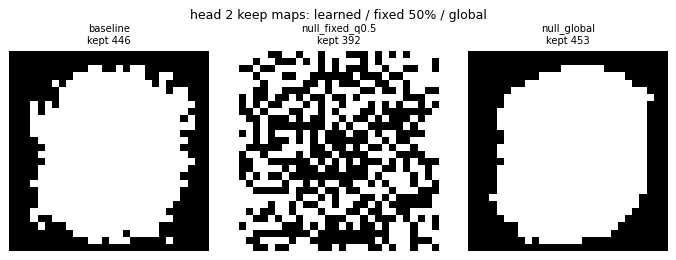

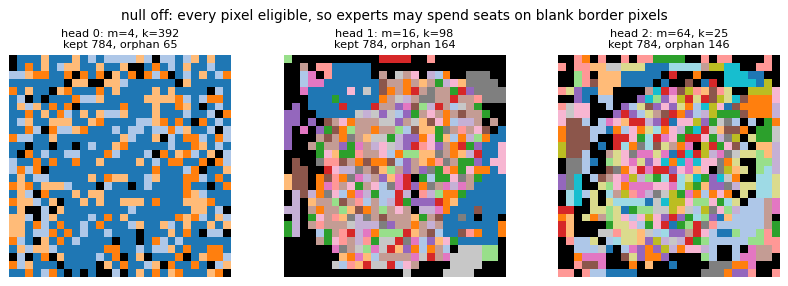

In [12]:
run("null_fixed_q0.5", model={"null_type": "fixed", "null_q": 0.5})
run("null_global", model={"null_mode": "global"})
run("null_off", model={"null_mode": "off"})
names = ["baseline", "null_fixed_q0.5", "null_global", "null_off"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "kept_h0", "kept_h1", "kept_h2", "orphan_h2"]))
show_keep(names[:3], h=2, title="head 2 keep maps: learned / fixed 50% / global")
show_maps("null_off", "null off: every pixel eligible, so experts may spend seats on blank border pixels")

**What we see.** On MNIST, *less* nulling gives slightly better reconstruction (`null_off` best,
`fixed 50%` next). With 20 epochs, the routing that results from more eligible pixels is easier to fit.
The cost shows in coverage: with the null off, head 2 has ~146 orphan pixels, and experts' seats go to
blank border pixels. `global` forces one shared kept set (~450) and doubles head 2's orphans relative
to per-head. Probes are within ±0.001 across all four. This matches MIMIC, where the null variants were
also within noise.

## 5. Initialisation and seed stability

### 5a. `gate_init`: `prior_corr` vs `random`; 5b. `train_gates`: learned vs frozen

* `prior_corr` starts every head from spectral clustering of the train |correlation| (k = m): +`init_scale`
  for the cluster's expert and −`init_scale` elsewhere, plus N(0, `init_noise`) jitter.
* `random` puts each unit in ⌈r⌉ random experts.
* `train_gates: false` freezes the initial assignment. This is a control: does *learning* the grouping
  help, and does it matter *which* pixels go together?
* **Affects:** where routing starts (and, partly, where it ends: from the prior start, routing moves ≈ 25%
  of memberships in head 0 and ≈ 50–55% in heads 1–2), reconstruction and seed-to-seed stability.
* `init_scale` (±2) sets how far the initial logits are from the selection boundary. Larger values make
  the initial assignment harder to leave.

random_init                  val 0.00575  test 0.00560  probe 0.9126  (30.5 s)


prior_frozen                 val 0.00542  test 0.00527  probe 0.9103  (22.8 s)


random_frozen                val 0.00538  test 0.00524  probe 0.9103  (22.6 s)


,val_recon,test_recon,probe_acc,changed_h0,changed_h1,changed_h2
baseline,0.005624,0.005468,0.9120,0.250,0.123,0.036
random_init,0.005754,0.005599,0.9126,0.177,0.042,0.012
prior_frozen,0.005415,0.005274,0.9103,0.000,0.000,0.000
random_frozen,0.005385,0.005240,0.9103,0.000,0.000,0.000


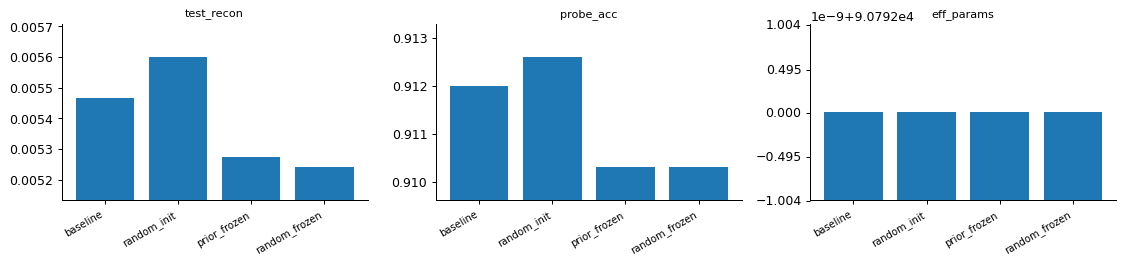

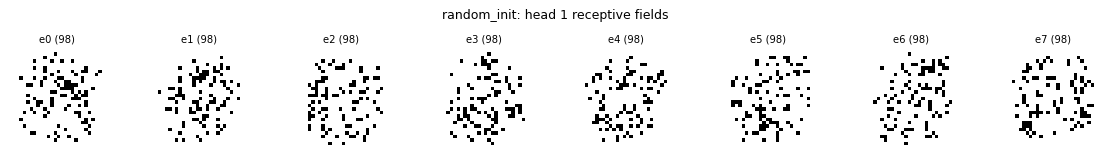

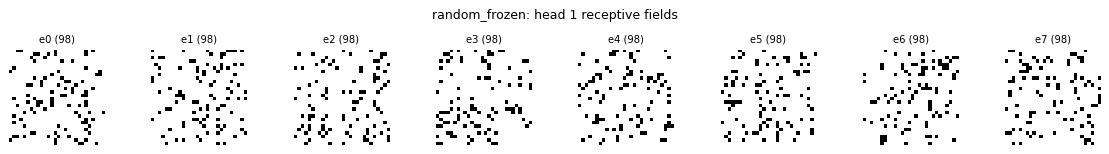

In [13]:
run("random_init", model={"gate_init": "random"})
run("prior_frozen", model={"train_gates": False})
run("random_frozen", model={"gate_init": "random", "train_gates": False})
names = ["baseline", "random_init", "prior_frozen", "random_frozen"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "changed_h0", "changed_h1", "changed_h2"]))
compare(names)
show_experts("random_init", 1, n=8, cols=8); show_experts("random_frozen", 1, n=8, cols=8)

**What we see. This is an honest negative result on MNIST.** The frozen controls reconstruct slightly
*better* than learned routing (≈ 0.0052–0.0053 vs 0.0055), with probes ~0.002 lower. Learning the
routing does not pay off for pixel reconstruction in a 20-epoch run: the gate-learning phase perturbs
the experts' inputs, and the frozen models get those epochs as clean training. `random_init` and the
prior start end up similar, although routing moves less from a random start (≈ 17–19% of memberships in
every head, vs ≈ 25–56% from the prior start). On MIMIC labs the picture was different (`prior_frozen` was clearly worse
than learned), so this knob is data-dependent. Treat `train_gates: false` as a mandatory control.

### 5c. Seed stability

Do two seeds find the same groups? For each pixel, take its primary expert in head h and compare two seeds
with the adjusted Rand index (ARI: 1 = identical partition up to relabelling, 0 = chance). Seed changes
the clustering seed, logit jitter, weight init and data order.

In [14]:
from sklearn.metrics import adjusted_rand_score

def primary(name, h):
    enc = RESULTS[name]["res"].model.encoder
    G, keep = hard(name)[h]
    return assignment_map(G, keep, enc.heads[h].gate.logits.detach().cpu().numpy()).ravel()

run("baseline_seed1", train={"seed": 1})
run("random_init_seed1", model={"gate_init": "random"}, train={"seed": 1})
rows = []
for a, b in [("baseline", "baseline_seed1"), ("random_init", "random_init_seed1")]:
    rows.append({"pair": f"{a} vs {b}", **{f"ARI_h{h}": round(adjusted_rand_score(primary(a, h), primary(b, h)), 3) for h in range(3)}})
pd.DataFrame(rows)

baseline_seed1               val 0.00554  test 0.00538  probe 0.9124  (33.9 s)


random_init_seed1            val 0.00570  test 0.00554  probe 0.9102  (31.2 s)


,pair,ARI_h0,ARI_h1,ARI_h2
0,baseline vs baseline_seed1,0.486,0.656,0.672
1,random_init vs random_init_seed1,0.461,0.648,0.749


**What we see.** Moderate stability (ARI ≈ 0.46–0.75), higher in finer heads. The prior does *not* make
the groups more stable here than random init. Part of the ARI comes from the shared null (both seeds drop
the same border), which the primary-expert labels count as one group.

## 6. The gate schedule (`phases.*`)

| key | controls | affects |
|---|---|---|
| `warmup_end` | epochs of dense training before any gate acts | how good the expert weights are when routing starts. 0 means routing decisions are made by random weights. |
| `harden_start` | when gates become fixed 0/1 | how long routing can explore; later hardening means more change but less fine-tuning time |
| `lambda_ramp_end` | how fast the regularizers ramp in | early pressure on the null and the logits |
| `temp_start`, `temp_end` | hard-concrete temperature (keep gates, column gates, concrete budget) and the scale of `ec_noise` | stochasticity of the null during learning. Routing itself is deterministic top-k, so temperature does not affect it unless `ec_noise > 0`. |
| `gate_lr_mult` | gate-logit LR / weight LR during gate learning | **how far routing moves** from the initial assignment |
| `finetune_lr_mult` | weight LR after hardening | final fit of the sparse model |

gate_lr_x1                   val 0.00591  test 0.00575  probe 0.9111  (31.9 s)


gate_lr_x30                  val 0.00549  test 0.00534  probe 0.9122  (31.5 s)


no_warmup                    val 0.00540  test 0.00525  probe 0.9129  (35.4 s)


,val_recon,test_recon,probe_acc,changed_h0,changed_h1,changed_h2,kept_h2
gate_lr_x1,0.005910,0.005753,0.9111,0.054,0.097,0.015,784.0
baseline,0.005624,0.005468,0.9120,0.250,0.123,0.036,446.0
gate_lr_x30,0.005489,0.005335,0.9122,0.255,0.143,0.040,402.0
no_warmup,0.005399,0.005252,0.9129,0.233,0.122,0.033,410.0


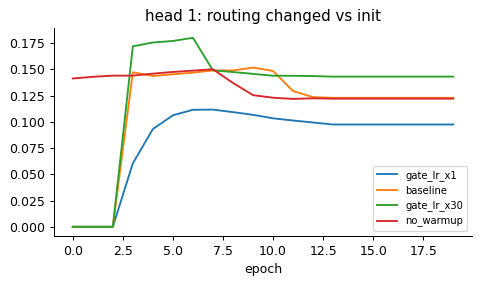

In [15]:
run("gate_lr_x1", model={"phases": {"gate_lr_mult": 1.0}})
run("gate_lr_x30", model={"phases": {"gate_lr_mult": 30.0}})
run("no_warmup", model={"phases": {"warmup_end": 0}})
names = ["gate_lr_x1", "baseline", "gate_lr_x30", "no_warmup"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "changed_h0", "changed_h1", "changed_h2", "kept_h2"]))
fig, ax = plt.subplots(figsize=(6, 3))
for n in names:
    ax.plot(RESULTS[n]["res"].history.epoch, RESULTS[n]["res"].history.h1_changed_vs_init, label=n)
ax.set_title("head 1: routing changed vs init"); ax.set_xlabel("epoch"); ax.legend(fontsize=8); plt.show()

**What we see.** `gate_lr_mult` is the main lever on how far gates move. At ×1 the keep logits never get
from +3 to the boundary (head 2 keeps all 784), and head 0's routing barely moves (5% vs 25% of memberships;
heads 1 and 2: ≈ 39% and ≈ 24% vs ≈ 49% and ≈ 56%). Going from
×10 to ×30 changes little more. Skipping the dense warm-up did *not* hurt on MNIST (slightly better recon),
in line with the frozen-routing result: here the experts' weights adapt easily to whatever routing they
get.

## 7. Expert-choice gradient, exploration and `lambda_mem`

The forward pass is a hard top-k per expert. The routing logits learn through a straight-through
surrogate:

* `ec_surrogate: sigmoid` (default, as in the original runs): each (unit, expert) logit gets gradient
  through sigmoid(logit). Units learn independently whether they would help that expert.
* `ec_surrogate: softmax`: the surrogate is k·softmax over units per expert, so units **compete** for an
  expert's seats (raising one unit's score lowers the others').
* `ec_noise` > 0 adds Gumbel noise × temperature to the scores before top-k during gate learning. Units
  near the boundary are sometimes swapped in and get a forward-pass signal. The noise anneals with the
  temperature.
* `lambda_mem`: the membership cap from feature-choice M-MoE. Under expert choice it acts on
  sigmoid(logits), so it is only a weak shrinkage of the routing logits; the ranking decides membership.
  Expect little effect.

ec_softmax                   val 0.00561  test 0.00546  probe 0.9125  (35.9 s)


ec_noise1                    val 0.00708  test 0.00691  probe 0.9103  (37.5 s)


lambda_mem=0                 val 0.00568  test 0.00553  probe 0.9130  (31.7 s)


lambda_mem=0.1               val 0.00569  test 0.00554  probe 0.9110  (34.0 s)


,val_recon,test_recon,probe_acc,changed_h0,changed_h1,changed_h2,orphan_h2
baseline,0.005624,0.005468,0.9120,0.250,0.123,0.036,21.0
ec_softmax,0.005615,0.005462,0.9125,0.256,0.126,0.034,11.0
ec_noise1,0.007084,0.006911,0.9103,0.299,0.160,0.045,55.0
lambda_mem=0,0.005683,0.005527,0.9130,0.266,0.138,0.042,13.0
lambda_mem=0.1,0.005691,0.005539,0.9110,0.253,0.121,0.024,3.0


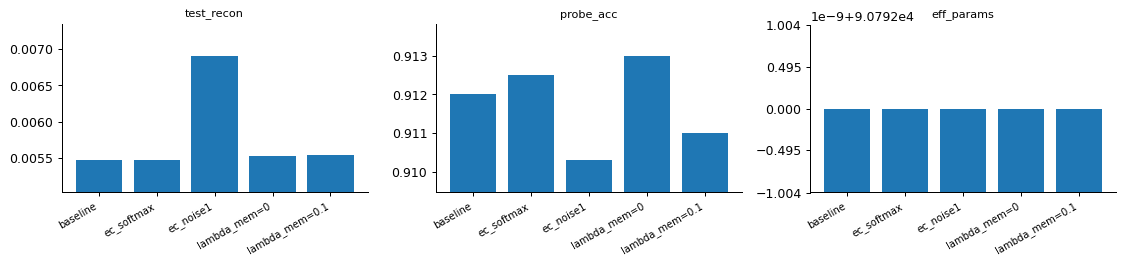

In [16]:
run("ec_softmax", model={"ec_surrogate": "softmax"})
run("ec_noise1", model={"ec_noise": 1.0})
run("lambda_mem=0", model={"lambda_mem": 0.0})
run("lambda_mem=0.1", model={"lambda_mem": 0.1})
names = ["baseline", "ec_softmax", "ec_noise1", "lambda_mem=0", "lambda_mem=0.1"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "changed_h0", "changed_h1", "changed_h2", "orphan_h2"]))
compare(names)

**What we see.** `softmax` ≈ `sigmoid` on every metric (slightly fewer orphans). `ec_noise = 1` explores
more (higher `changed_h*`) but clearly hurts reconstruction (≈ +25%) and leaves more orphans. The swaps
keep disturbing the experts, so smaller values (0.1–0.3) are the ones worth trying. `lambda_mem` hardly
changes recon or probe, but a large value (0.1) cuts head-2 orphans (21 → 3): shrinking every logit
evens out how often each unit is picked.

## 8. Global input budget: `input_budget` (K) and `budget_type`

A gate **in front of all heads** keeps exactly K features (feature selection inside the model). Capacity
then scales with the budget: k = ⌈r·K/m⌉.

* `budget_type: concrete` (default): K concrete selector units (Abid et al., 2019), each a Gumbel-softmax
  over all features. Every feature gets a gradient, and hardening picks K distinct features.
* `budget_type: topk`: one score per feature, straight-through top-K. A feature outside the top K is
  invisible to every expert, so its score gets **no gradient** and the initial (random) selection tends
  to freeze. This happened on MIMIC labs; it is kept as a documented negative result.
* **Affects:** which features are used at all, and reconstruction of the dropped ones (the decoder must
  still predict all 784 pixels).

budget_K50                   val 0.01399  test 0.01379  probe 0.8389  (44.4 s)


budget_K150                  val 0.00992  test 0.00968  probe 0.8886  (33.8 s)


budget_K150_topk             val 0.00857  test 0.00839  probe 0.8653  (41.0 s)


,val_recon,test_recon,probe_acc,in_kept,k_h0,k_h1,k_h2
budget_K50,0.013992,0.013789,0.8389,50.0,25.0,7.0,2.0
budget_K150,0.009919,0.009676,0.8886,150.0,75.0,19.0,5.0
budget_K150_topk,0.008575,0.008391,0.8653,150.0,75.0,19.0,5.0
null_off,0.005311,0.005166,0.9117,NaN,392.0,98.0,25.0


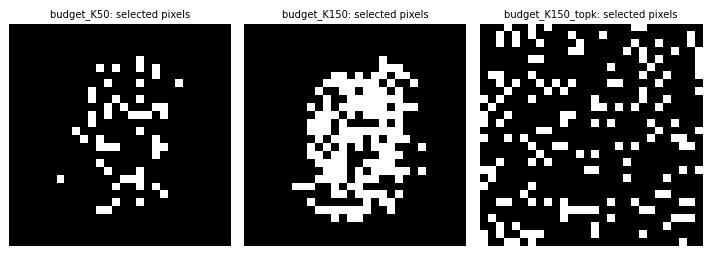

In [17]:
for K in (50, 150):
    run(f"budget_K{K}", model={"input_budget": K, "null_mode": "off"})
run("budget_K150_topk", model={"input_budget": 150, "null_mode": "off", "budget_type": "topk"})
names = ["budget_K50", "budget_K150", "budget_K150_topk", "null_off"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "in_kept", "k_h0", "k_h1", "k_h2"]))
fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, n in zip(axes, names[:3]):
    sel = RESULTS[n]["res"].model.encoder.input_gate.kept_hard().cpu().numpy()
    ax.imshow(sel.reshape(28, 28), cmap="gray"); ax.axis("off"); ax.set_title(f"{n}: selected pixels", fontsize=8)
plt.tight_layout(); plt.show()

**What we see.** The concrete selector learns: its K pixels concentrate in the digit area. The top-K
selection stays at its random initialisation, scattered over the whole image *including the always-blank
border*, which is the documented failure mode. Its reconstruction is nonetheless *better* at K = 150
(a uniform spatial sample is good for interpolating every pixel), but its probe is clearly worse
(≈ 0.865 vs 0.889). This is a reminder that recon loss alone can reward the wrong selection. Shrinking K
costs both recon and probe smoothly.

## 9. Missing data: `use_obs_flags`, `column_units`, `split_value_flag`

The original use case (lab tests) is mostly missing. To show the flag options, each MNIST image gets a
random **10×10 occluded square** (missing). Missing pixels are set to 0, and the observed mask is passed
to the model and the loss (only observed pixels count in the Huber term).

* `use_obs_flags: true`: input = [784 values, 784 was-observed flags]. A feature's value and flag share
  one routing unit, so an expert reads both or neither.
* `column_units: true`: value and flag are **separate units** (U = 1568), each with its own null gate and
  expert memberships. A head can use "pixel was occluded" without the value, or the reverse.
* `split_value_flag: true` (with a budget): separate L0-priced gates for each kept feature's value and
  flag column (`lambda_col`).
* `use_obs_flags: false`: the model sees zeros and cannot tell "missing" from "black".
* Training settings: `obs_bce_weight` (0.2) weights the decoder's flag-prediction BCE term, and
  `feature_loss_floor` re-weights rare features (unused on MNIST: every pixel is equally observed).

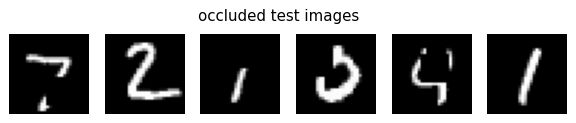

occ_values_only              val 0.00557  test 0.00547  probe 0.8212  (34.8 s)


occ_flags                    val 0.01257  test 0.01242  probe 0.8331  (37.9 s)


occ_column_units             val 0.01250  test 0.01236  probe 0.8419  (38.7 s)


occ_budget_split             val 0.02493  test 0.02476  probe 0.7848  (48.4 s)


,val_recon,test_recon,probe_acc,kept_h0,kept_h2,in_kept,in_both,in_value_only,in_flag_only
occ_values_only,0.005569,0.005470,0.8212,467.0,442.0,NaN,NaN,NaN,NaN
occ_flags,0.012569,0.012425,0.8331,777.0,775.0,NaN,NaN,NaN,NaN
occ_column_units,0.012504,0.012362,0.8419,1565.0,1566.0,NaN,NaN,NaN,NaN
occ_budget_split,0.024932,0.024761,0.7848,150.0,150.0,150.0,150.0,0.0,0.0


In [18]:
xo_tr, o_tr = occlude(Xtr, 10, seed=0); xo_va, o_va = occlude(Xva, 10, seed=1); xo_te, o_te = occlude(Xte, 10, seed=2)
OCC = {"train": (xo_tr, o_tr), "val": (xo_va, o_va), "test": (xo_te, o_te)}
plt.figure(figsize=(8, 1.5))
for i in range(6):
    plt.subplot(1, 6, i + 1); plt.imshow(xo_te[i].reshape(28, 28), cmap="gray"); plt.axis("off")
plt.suptitle("occluded test images"); plt.show()

run("occ_values_only", model={"use_obs_flags": False}, data=OCC)
run("occ_flags", model={"use_obs_flags": True}, data=OCC)
run("occ_column_units", model={"use_obs_flags": True, "column_units": True}, data=OCC)
run("occ_budget_split", model={"use_obs_flags": True, "input_budget": 150, "null_mode": "off", "split_value_flag": True}, data=OCC)
names = ["occ_values_only", "occ_flags", "occ_column_units", "occ_budget_split"]
display(table(names, ["val_recon", "test_recon", "probe_acc", "kept_h0", "kept_h2", "in_kept", "in_both", "in_value_only", "in_flag_only"]))

Recon losses are not directly comparable between `occ_values_only` and the flag models: the flag models
also pay `obs_bce_weight × BCE` for predicting the mask, and `occ_values_only` is scored on every pixel
(occluded zeros included). Compare `probe_acc` across them, and recon only within the flag models.

**What we see.** Telling the model what is missing helps: probe ≈ 0.821 (values only), 0.833 (flags) and
0.842 (separate value/flag units). This is the same ordering as on MIMIC labs, where `mmoe_ec_cols` gave
the best M-MoE probes. With the budget + split, `lambda_col = 1e-3` was too weak to close any column
(all 150 kept pixels use value and flag), and the 150-pixel budget costs accuracy as in section 8.

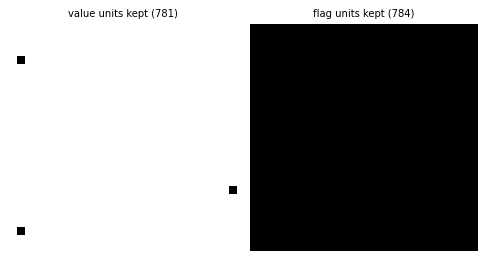

In [19]:
# column_units: which value units and which flag units does head 0 keep?
G, keep = hard("occ_column_units")[0]
fig, axes = plt.subplots(1, 2, figsize=(5.5, 3))
axes[0].imshow(keep[:784].reshape(28, 28), cmap="gray"); axes[0].set_title(f"value units kept ({int(keep[:784].sum())})", fontsize=8)
axes[1].imshow(keep[784:].reshape(28, 28), cmap="gray"); axes[1].set_title(f"flag units kept ({int(keep[784:].sum())})", fontsize=8)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 10. Summary of all runs

In [20]:
cols = ["val_recon", "test_recon", "probe_acc", "eff_params", "kept_h0", "kept_h1", "kept_h2",
        "orphan_h2", "mem_h2", "changed_h1", "seconds"]
summary = table(list(RESULTS), cols)
summary.style.format(precision=4).background_gradient(subset=["test_recon"], cmap="RdYlGn_r") \
       .background_gradient(subset=["probe_acc"], cmap="RdYlGn")

,val_recon,test_recon,probe_acc,eff_params,kept_h0,kept_h1,kept_h2,orphan_h2,mem_h2,changed_h1,seconds
baseline,0.0056,0.0055,0.9120,90792.0000,489.0000,491.0000,446.0000,21.0000,3.5900,0.1230,38.1000
heads=[4],0.0118,0.0117,0.8285,25864.0000,507.0000,nan,nan,nan,nan,nan,16.2000
heads=[16],0.0072,0.0070,0.8933,28000.0000,465.0000,nan,nan,nan,nan,nan,16.7000
heads=[64],0.0059,0.0057,0.9077,37056.0000,391.0000,nan,nan,nan,nan,nan,18.5000
u8_de1,0.0061,0.0059,0.9115,44756.0000,482.0000,496.0000,459.0000,19.0000,3.4900,0.1320,26.5000
u32_de4,0.0052,0.0051,0.9141,186896.0000,490.0000,486.0000,447.0000,27.0000,3.5800,0.1030,31.0000
r=1,0.0059,0.0057,0.9102,53416.0000,454.0000,422.0000,414.0000,51.0000,2.0100,0.0630,33.0000
r=4,0.0055,0.0053,0.9135,146856.0000,492.0000,519.0000,480.0000,5.0000,6.5300,0.2160,32.6000
lambda_null=0,0.0056,0.0055,0.9124,90792.0000,784.0000,784.0000,784.0000,146.0000,2.0400,0.1540,33.2000
lambda_null=0.01,0.0056,0.0055,0.9120,85352.0000,307.0000,383.0000,337.0000,1.0000,4.7500,0.1160,32.9000


### Cheat sheet: what each hyperparameter moves

| hyperparameter | primary effect | watch |
|---|---|---|
| `experts_per_head` | granularity of groups; multi-head = several granularities at once | `probe_h*`, receptive fields |
| `expert_hidden`, `expert_out` | capacity per group / per-group bottleneck | recon, `eff_params` |
| `r`, `capacity` | seats per expert → overlap, orphans, sparsity | `mem_h*`, `orphan_h*`, `eff_params` |
| `lambda_null` | how many units each head drops | `kept_h*`, keep maps |
| `null_type`, `null_q` | learned vs fixed null size (control) | `kept_h*` |
| `null_mode` | per-head vs shared vs no null | keep maps, orphans |
| `gate_init`, `init_scale`, `init_noise` | where routing starts and how sticky the start is | `changed_h*`, ARI across seeds |
| `train_gates` | learned vs frozen routing (control) | recon/probe gap to baseline |
| `phases.gate_lr_mult` | how far routing moves | `changed_h*` |
| `phases.warmup_end` | quality of weights when routing starts | recon, `changed_h*` |
| `phases.temp_*` | stochasticity of keep / budget gates and `ec_noise` | `kept_h*` trajectory |
| `ec_surrogate`, `ec_noise` | how the top-k is learned / explored | `changed_h*`, orphans |
| `lambda_mem` | weak shrinkage of routing logits under EC | (little) |
| `input_budget`, `budget_type` | global feature selection, exactly K | selected maps, recon |
| `use_obs_flags`, `column_units`, `split_value_flag`, `lambda_col` | how missingness enters and is routed | value/flag units kept |

See `README.md` for the full list with defaults and caveats.